## Heat Equation Simulation

This notebook simulates the heat/temperature profile for the partial derivative heat equation provided below:

$$ \frac {\partial u}{\partial t} = \alpha \frac {\partial^2 u}{\partial x^2} $$

Where $$ u = Temperature [K] $$ and $$ x = Length [m] $$ 

The workings showcases how the PDE system for the reactor will be handled. Finite volume discretisation will be the method used to solve and implement the heat equation PDE.

## Import Libraries

In [151]:
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

## Parameters

The code requires the following parameter:

| Mathematical symbol | Variable name | Description |
| --- | --- | --- |
| $ \alpha $ | `alpha` | Thermal diffusivity ( $m^2$/s).|
|$L$| `L` | Length of rod ($m$).|
|$n$|`n`| Number of cells.|
|$\Delta x$|`dx`| Spatial step size ($m$).|

Where 
$ dx = \frac{L}{n} $

Using these parameters, it can calculate the the temperature of the system along the x axis.

In [152]:
alpha = {'H2O': 0.143*10**-6, 'air': 0.19*10**-6} #thermal diffusivity of water and air in m^2/s
L = 1.0 # length of rod along the x-axis in meters
n = 10 # number of grid cells along the rod
dx = L / n #spatial step size

## Grid Cells
$u_i$ represents the average temperature of cell $i$, stored at the centre of the cell. The position of point $i$ along the x-axis is depicted as:

$$
x_i = (i-\frac {1}{2})\Delta x, \  i = 1,2,3......,N
$$

In [153]:
x = np.linspace(dx/2, L-dx/2, n) #spatial domain from 0 to L meters with N points

## Boundary Conditions Handling

The first cell and last cells both have two sides but only have one neighbouring cell each. The other side of these cells are the boundaries of the rod. Therefore, the equations are handled differently to the interior cells.

The discretised equations for the first and last cell of the rod are as follows:

$$ 
\frac{\partial u_1}{\partial t} \approx \frac {\alpha}{\Delta x^2} (2T_L - 3u_1 + u_2 ) \ \left[\frac{K}{s}\right]
$$

$$
\frac{\partial u_N}{\partial t} \approx \frac {\alpha}{\Delta x^2} (u_{N-1} - 3u_N + 2T_R ) \ \left[\frac{K}{s}\right]
$$



In [154]:
#Constants for boundary conditions on the left and right hand side of the system boundary
T_L, T_R = 25 + 273.15, 60 + 273.15 # converting to Kelvin

#First cell 
def first_cell(u_cell):
    u1 = alpha['H2O'] *(2*T_L - 3*u_cell[0] + u_cell[1])/dx**2
    return u1

#Last cell
def last_cell(u_cell):
    uN = alpha['H2O'] *(u_cell[-2] - 3*u_cell[-1] + 2*T_R )/dx**2

    return uN

## Interior Cells

The equation for the discretised PDE $\frac{\partial^2 u}{\partial x^2}$, for the internal cells is shown below:

$$ 
\left. \frac{\partial^2 u}{\partial x^2} \right|_{x_i} \approx \frac {u_{i-1} - 2u_i + u_{i+1}}{\Delta x^2} 
$$ 

Where $ i = 2,3,..., N-1$

In [155]:
def interior_cells(u_cell):
    du_dt = np.zeros(n-2) #empty array to store the second derivative values for each interior point

    for i in range(1, n-1):
        du_dt[i-1] = alpha['H2O'] *(u_cell[i-1] - 2*u_cell[i] + u_cell[i+1])/dx**2

    return du_dt

## Full heat equation

The cell below combines the first, interior and last cells equation to create the full discretised PDE

In [156]:
def heatequation(u_cell):
    du_dt = np.concatenate(([first_cell(u_cell)], interior_cells(u_cell), [last_cell(u_cell)]))
    return du_dt

## Steady-state system

For a steady-state system, 

$$ \frac{\partial u}{\partial t} = 0 $$

Therefore, the heat equation simplifies into a linear algebraic as shown below: 

$$ 
0 = \left. \frac{\partial^2 u}{\partial x^2} \right|_{x_i} \approx \frac {\alpha}{\Delta x^2} (\ u_{i-1} - 2u_i + u_{i+1})  \ \left[\frac{K}{s}\right]
$$

In [157]:
u_guess = np.linspace(u_1, u_N, n) #initial guesses for the cells
u_ss = fsolve(heatequation, u_guess) #solving for the interior points using fsolve
print("The steady-state solution in Kelvin is:" , np.round(u_ss, 2))

The steady-state solution in Kelvin is: [299.9 303.4 306.9 310.4 313.9 317.4 320.9 324.4 327.9 331.4]


## Steady-state temperature profile

The below code results in an illustration of the steady-state change in temperature along the rod.

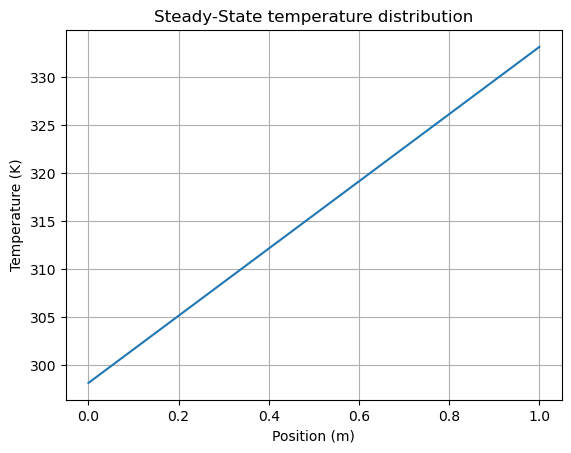

In [158]:
T = np.concatenate(([u_1], u_ss, [u_N])) # add boundary conditions to the interior solution
x_plot = np.concatenate(([0], x, [L])) # add boundary points to the spatial domain
plt.plot(x_plot, T)
plt.xlabel('Position (m)')
plt.ylabel('Temperature (K)')
plt.title('Steady-State temperature distribution')
plt.grid()

## Dynamic System

This section of the code looks at the transient solution for the heat equation.

The equation for the discretised PDE $\frac{\partial^2 u}{\partial x^2}$, is shown below:

$$ 
\frac{\partial u}{\partial t} = \frac{\partial^2 u}{\partial x^2} \approx \frac {\alpha}{{\Delta x^2}}(u_{i-1} - 2u_i + u_{i+1}) \  \left[\frac{K}{s}\right]
$$ 

In [159]:
def transient(t, u_cell):
    du_dt = heatequation(u_cell)

    return du_dt

u_guess = np.linspace(u_1, u_1, n) #initial guess for the interior points
t0, t = 0, 3600*24 #time span for the simulation

sol = solve_ivp(transient, [t0, t], u_guess,t_eval=np.linspace(t0, t, 100), method='BDF') #solving for the interior points using solve_ivp; BDF method used for the stiffness of the system

#adding boundary conditions for the full temperature profile at each time step
u_full = sol.y

## Transient-state temperature profile

The below code illustrates the transient temperature behaviour along the rod. 

(ALL CODE BELOW GENERATED BY CLAUDE IN ORDER TO GET A LIVE ANIMATION AS DISCUSSED IN PREVIOUS PROGRESS MEETING)

In [160]:
x_plot = np.concatenate(([0], x, [L]))                                           # m, length 12
u_plot = np.vstack([np.full(sol.t.size, T_L), u_full, np.full(sol.t.size, T_R)])  # K, shape (12, 100)

fig, ax = plt.subplots()
line, = ax.plot(x_plot, u_plot[:, 0])             # profile at the first stored time, including both rod ends
ax.set_xlim(0, L)
ax.set_ylim(u_plot.min() - 1, u_plot.max() + 1)   # fixed axes so the plot does not jump
ax.set_xlabel('x (m)')
ax.set_ylabel('Temperature (K)')
title = ax.set_title('')

def update(frame):
    line.set_ydata(u_plot[:, frame])              # column = full profile at one time
    title.set_text(f't = {sol.t[frame] / 86400:.1f} days')
    return line, title

anim = FuncAnimation(fig, update, frames=sol.t.size, interval=50)
plt.close(fig)                                    # stops a duplicate static figure
HTML(anim.to_jshtml())

In [161]:
fig, ax = plt.subplots(figsize=(10, 3))
strip = u_full[:, 0][np.newaxis, :]               # shape (1, 10): one row, one column per cell

image = ax.imshow(strip, aspect='auto', cmap='inferno',
                  extent=[0, L, 0, 1],
                  vmin=u_full.min(), vmax=u_full.max())   # fixed colour range
ax.set_yticks([])
ax.set_xlabel('Position (m)')
ax.set_title('Heat Equation Solution: Temperature Distribution in Rod')
fig.colorbar(image, ax=ax, label='Temperature (K)')
time_label = ax.text(0.02, 0.9, '', transform=ax.transAxes, color='white')

def update(frame):
    image.set_data(u_full[:, frame][np.newaxis, :])
    time_label.set_text(f't = {sol.t[frame] / 86400:.1f} days')
    return image, time_label

anim = FuncAnimation(fig, update, frames=sol.t.size, interval=50)
plt.close(fig)
HTML(anim.to_jshtml())